In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [2]:
housing = fetch_california_housing(as_frame=True)
X, y = housing.data, housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(16512, 8) (4128, 8)


In [3]:
modeles = {
    "Régression linéaire": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (α=1)":         make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso (α=0.01)":      make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
    "KNN (k=10)":          make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "Arbre de décision":   DecisionTreeRegressor(random_state=42),
    "Random Forest":       RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    "Gradient Boosting":   HistGradientBoostingRegressor(random_state=42),
}

In [4]:
resultats = []
for nom, modele in modeles.items():
    debut = time.time()
    modele.fit(X_train, y_train)
    duree = time.time() - debut

    pred_train = modele.predict(X_train)
    pred_test = modele.predict(X_test)

    resultats.append({
        "Modèle": nom,
        "MAE test": mean_absolute_error(y_test, pred_test),
        "RMSE test": root_mean_squared_error(y_test, pred_test),
        "R² train": r2_score(y_train, pred_train),
        "R² test": r2_score(y_test, pred_test),
        "Temps (s)": duree,
    })
    print(f"{nom} : terminé en {duree:.1f} s")

df_res = pd.DataFrame(resultats).sort_values("RMSE test").reset_index(drop=True)
df_res.round(3)

Régression linéaire : terminé en 0.2 s
Ridge (α=1) : terminé en 0.0 s
Lasso (α=0.01) : terminé en 0.1 s
KNN (k=10) : terminé en 0.2 s
Arbre de décision : terminé en 0.4 s
Random Forest : terminé en 8.6 s
Gradient Boosting : terminé en 1.0 s


,Modèle,MAE test,RMSE test,R² train,R² test,Temps (s)
0,Gradient Boosting,0.311,0.465,0.880,0.835,0.973
1,Random Forest,0.328,0.506,0.974,0.805,8.568
2,KNN (k=10),0.440,0.649,0.755,0.678,0.170
3,Arbre de décision,0.454,0.703,1.000,0.623,0.355
4,Lasso (α=0.01),0.535,0.740,0.608,0.582,0.131
5,Ridge (α=1),0.533,0.746,0.613,0.576,0.029
6,Régression linéaire,0.533,0.746,0.613,0.576,0.177


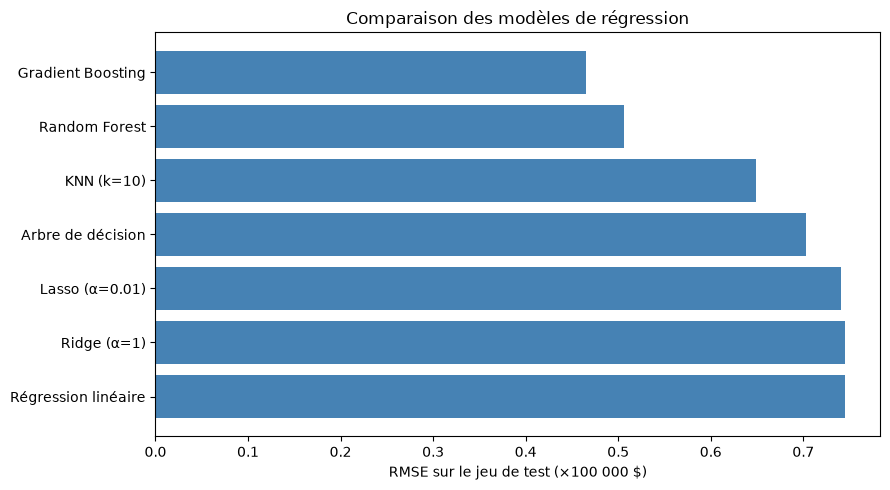

In [5]:
plt.figure(figsize=(9, 5))
plt.barh(df_res["Modèle"], df_res["RMSE test"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("RMSE sur le jeu de test (×100 000 $)")
plt.title("Comparaison des modèles de régression")
plt.tight_layout()
plt.savefig("../figures/comparaison_rmse.png", dpi=150)
plt.show()

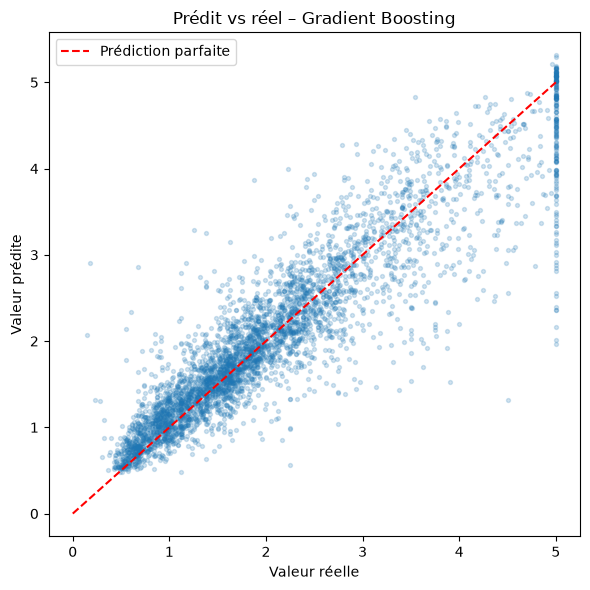

In [6]:
meilleur_nom = df_res.loc[0, "Modèle"]
pred = modeles[meilleur_nom].predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.2, s=8)
plt.plot([0, 5], [0, 5], "r--", label="Prédiction parfaite")
plt.xlabel("Valeur réelle"); plt.ylabel("Valeur prédite")
plt.title(f"Prédit vs réel – {meilleur_nom}")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/predit_vs_reel.png", dpi=150)
plt.show()

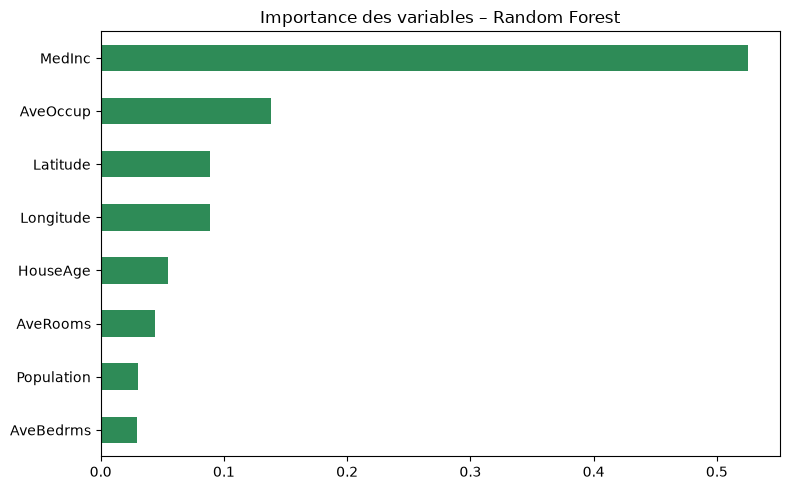

In [7]:
importances = pd.Series(
    modeles["Random Forest"].feature_importances_, index=X.columns
).sort_values()

importances.plot(kind="barh", figsize=(8, 5), color="seagreen")
plt.title("Importance des variables – Random Forest")
plt.tight_layout()
plt.savefig("../figures/importance_variables.png", dpi=150)
plt.show()

In [8]:
coefs = pd.Series(
    modeles["Régression linéaire"][-1].coef_, index=X.columns
).sort_values()
coefs

Latitude     -0.896929
Longitude    -0.869842
AveRooms     -0.294410
AveOccup     -0.040829
Population   -0.002308
HouseAge      0.122546
AveBedrms     0.339259
MedInc        0.854383
dtype: float64

In [9]:
for nom in ["Régression linéaire", "Random Forest", "Gradient Boosting"]:
    scores = cross_val_score(modeles[nom], X_train, y_train, cv=5,
                             scoring="neg_root_mean_squared_error", n_jobs=-1)
    print(f"{nom} : RMSE moyen = {-scores.mean():.3f} (± {scores.std():.3f})")

Régression linéaire : RMSE moyen = 0.721 (± 0.010)
Random Forest : RMSE moyen = 0.511 (± 0.005)
Gradient Boosting : RMSE moyen = 0.473 (± 0.005)
